# Today we will work with `MNIST` dataset which is a dataset of 70k images of handwritten digits. The images are of very low resolution of 28*28 pixels. We will train with ANN.

In [1]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

In [3]:
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [4]:
x_train[0]

# These are 28*28 = 784 pixels of first image and we have 70k such images


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [5]:
# y_train contains digits on corresponding image

y_train[0]

# So first image contains digit 5

5

In [10]:
# We can also convert these pixel values on an image. Let's see that

import matplotlib.pyplot as plt

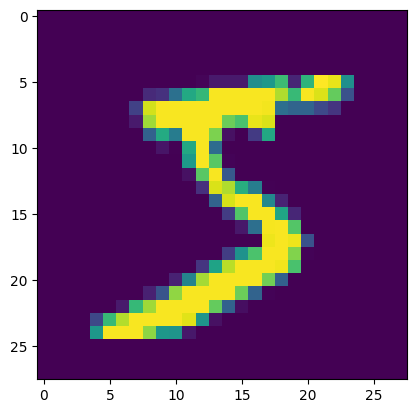

In [11]:
plt.imshow(x_train[0])

# As seen above, it is 5

In [ ]:
# Pixel values are always betweeen 0 and 255. Here also our images contains values between 0 and 255.
# So we will have to convert these values between 0 and 1 
# by dividing each pixel by the maximum value, which is 255

In [9]:
x_train = x_train/255
x_test = x_test/255

In [10]:
x_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [11]:
# Let's create our model now

model = Sequential()

model.add(Flatten(input_shape = (28, 28)))
model.add(Dense(128, activation = 'relu'))    # Input layer input_spahe already passed in Flatten layer
model.add(Dense(10, activation = 'softmax'))  # Output layer

# Activation for output layer is softmax bcz whenever we have more than 2 outputs, we'll use softmax

In [12]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 128)               100480    
                                                                 
 dense_1 (Dense)             (None, 10)                1290      
                                                                 
Total params: 101770 (397.54 KB)
Trainable params: 101770 (397.54 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [13]:
model.compile(loss = 'sparse_categorical_crossentropy', optimizer = 'Adam', metrics = ['accuracy'])

# We can also use los = 'categorical_crossentropy' but here we're using 'sparse_categorical_crossentropy'
# bcz in categorical_ce we have to OneHot encode our labels which is 0 to 9 but it is avoidable in
# Sparse_categorical_ce.

In [14]:
history = model.fit(x_train, y_train, epochs = 10, validation_split = 0.2)

Epoch 1/10
1500/1500 [==============================] - 11s 6ms/step - loss: 0.2853 - accuracy: 0.9197 - val_loss: 0.1517 - val_accuracy: 0.9569
Epoch 2/10
1500/1500 [==============================] - 9s 6ms/step - loss: 0.1263 - accuracy: 0.9631 - val_loss: 0.1137 - val_accuracy: 0.9664
Epoch 3/10
1500/1500 [==============================] - 9s 6ms/step - loss: 0.0872 - accuracy: 0.9746 - val_loss: 0.0958 - val_accuracy: 0.9719
Epoch 4/10
1500/1500 [==============================] - 9s 6ms/step - loss: 0.0650 - accuracy: 0.9805 - val_loss: 0.1034 - val_accuracy: 0.9690
Epoch 5/10
1500/1500 [==============================] - 9s 6ms/step - loss: 0.0503 - accuracy: 0.9846 - val_loss: 0.0835 - val_accuracy: 0.9750
Epoch 6/10
1500/1500 [==============================] - 9s 6ms/step - loss: 0.0382 - accuracy: 0.9885 - val_loss: 0.0904 - val_accuracy: 0.9721
Epoch 7/10
1500/1500 [==============================] - 9s 6ms/step - loss: 0.0305 - accuracy: 0.9906 - val_loss: 0.0835 - val_accuracy

In [16]:
pred = model.predict(x_test)

# Here, as we have used softmax activation function for out output layer,
# in prediction we will get the probability for each digit
# But in our output we want to show what is the digit.
# So we will have to find out at what index, we have max probability, for each image.

# The reason is simple, we have digits from 0 to 9
# IF the prob of 5th index is max, it means the digit is 4 (index is counted from 0)
# If the prob at 7th index is max, it means the image is 6

313/313 [==============================] - 1s 3ms/step


In [19]:
pred2 = pred.argmax(axis = 1)

pred2

# 7, 2, 1... shows that the first test image according to model, is 7 second is 2, third is 1 and so on

array([7, 2, 1, ..., 4, 5, 6], dtype=int64)

In [21]:
from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test, pred2)
acc

0.9789

In [22]:
history    # Returns a history object

In [23]:
history.history

# Returns a dict of loss, accuracy, val_loss and val_acciracy of all the epochs

{'loss': [0.2853301465511322,
  0.12630188465118408,
  0.08717665821313858,
  0.06498858332633972,
  0.05030939728021622,
  0.038217004388570786,
  0.030509071424603462,
  0.024116354063153267,
  0.01929178647696972,
  0.015777533873915672],
 'accuracy': [0.9196875095367432,
  0.9630833268165588,
  0.9745833277702332,
  0.9805416464805603,
  0.9846041798591614,
  0.9884791374206543,
  0.9905624985694885,
  0.992354154586792,
  0.9943541884422302,
  0.9949583411216736],
 'val_loss': [0.15166088938713074,
  0.11372898519039154,
  0.09579047560691833,
  0.10338430851697922,
  0.08346367627382278,
  0.09036734700202942,
  0.08353149890899658,
  0.08949443697929382,
  0.08459974825382233,
  0.0837179645895958],
 'val_accuracy': [0.9569166898727417,
  0.9664166569709778,
  0.971916675567627,
  0.968999981880188,
  0.9750000238418579,
  0.972083330154419,
  0.9752500057220459,
  0.9741666913032532,
  0.9776666760444641,
  0.9774166941642761]}

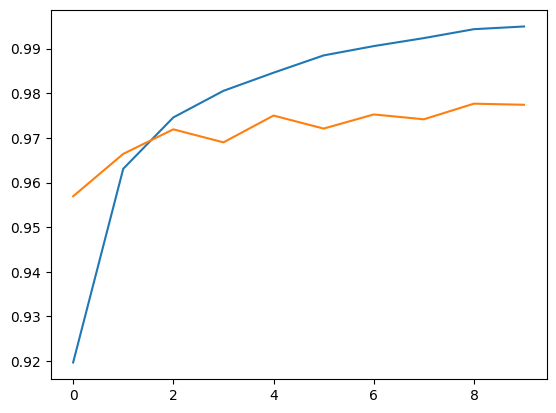

In [24]:
# plotting graph of training and validation accuracy

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

# Here we can see that our training accuracy reached to 100% but validation accuracy to 98%
# Hence we are seeing the gap between training and validation line.
# This gap indicated the overfitting of the model
# There are various ways to deal with overfitting

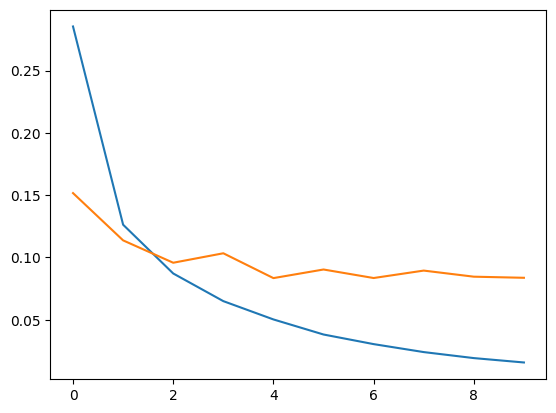

In [25]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

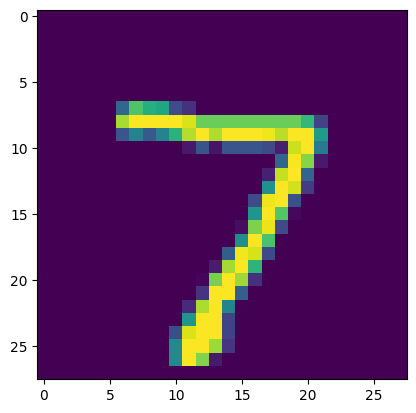

In [48]:
# Let's check our model

plt.imshow(x_test[0])

In [49]:
model.predict(x_test[0].reshape(1,28,28)).argmax(axis = 1)

1/1 [==============================] - 0s 75ms/step


array([7], dtype=int64)

In [50]:
x_test[0].ndim

2

In [51]:
x_test[0].reshape(1,28,28).ndim

3

# We can make some changes to increase the accuracy
* We can increase no_of epochs
* We can increase no_of nodes in the layers
* We can increase no_of layers.
* Generally it is seen that a model performs better if the activation function of the hidden layer is kept 'relu'

`All these ways are experimental, we cannot decide which particular change to be done.`